<font size = "5"> **[Image Tools](2_Image_Tools.ipynb)** </font>

<hr style="height:2px;border-top:4px solid #FF8200" />


# Structure Analysis

[<img src=https://www.coeuscreativegroup.com/wp-content/uploads/2020/04/download-button.png, width=125>](https://raw.githubusercontent.com/pycroscopy/pyTEMlib/main/notebooks/Imaging/I4_Structure_Analysis.ipynb) 

[![OpenInColab](https://colab.research.google.com/assets/colab-badge.svg)](
    https://colab.research.google.com/github/pycroscopy/pyTEMlib/blob/main/notebooks/Imaging/I4_Structure_Analysis.ipynb)

by 

Gerd Duscher

Materials Science & Engineering<br>
Joint Institute of Advanced Materials<br>
The University of Tennessee, Knoxville

We us this notebook **only** for a stack of images.


## Install pyTEMlib

If you have not done so in the [Introduction Notebook](1_Correcting_Image_Distortions.ipynb), please install [pyTEMlib](https://github.com/gduscher/pyTEMlib) with the code cell below.

In [1]:
import sys
import importlib.metadata
def test_package(package_name):
    """Test if package exists and returns version or -1"""
    try:
        version = importlib.metadata.version(package_name)
    except importlib.metadata.PackageNotFoundError:
        version = '-1'
    return version

if test_package('pyTEMlib') < '0.2026.1.0':
    print('installing pyTEMlib')
    !{sys.executable} -m pip install  --upgrade pyTEMlib -q
print('done')


done


## Import the usual libraries


You'll need at least pyTEMlib version 0.2020.04.2

You can load that library with the code cell above:

In [1]:
# import matplotlib and numpy
#                       use "inline" instead of "notebook" for non-interactive
#                       use widget for jupyterlab needs ipympl to be installed
# import matplotlib and numpy
%matplotlib widget  
import matplotlib.pylab as plt
import numpy as np

import sys
if 'google.colab' in sys.modules:
    from google.colab import output
    output.enable_custom_widget_manager()
    from google.colab import drive


%load_ext autoreload
%autoreload 2    

sys.path.insert(0, '../../')
import pyTEMlib

# For archiving reasons it is a good idea to print the version numbers out at this point
print('pyTEM version: ', pyTEMlib.__version__)
if 'google.colab' in sys.modules:
    drive.mount("/content/drive")
## Do all of registration

notebook_tags= {'notebook': 'Structure Analysis',
                'notebook_version': '2025_03_16',
                'pyTEM version': pyTEMlib.__version__}

pyTEM version:  0.2026.9.0


In [805]:
# --------------- INPUT ------------------------
zone_hkl = np.array([1, 2, -2])
hkl_max = 34 #  maximum allowed Miller index
Sg_max = 0.03   # 1/Ang  maximum allowed excitation error

acceleration_voltage_V = 200.0 * 1000.0 #V
# -------------------------------------------
atoms = pyTEMlib.crystal_tools.structure_by_name('silicon')

hkl_all = pyTEMlib.diffraction_tools.get_all_miller_indices(hkl_max)
# all evaluated reciprocal_unit_cell points
g_non_rot = np.dot(hkl_all, atoms.cell.reciprocal())

ewald = pyTEMlib.diffraction_tools.ewald_sphere_center(acceleration_voltage_V, atoms, zone_hkl)

k0_magnitude = np.linalg.norm(ewald)

s = (k0_magnitude**2-np.linalg.norm(g_non_rot - ewald, axis=1)**2)/(2*k0_magnitude)

reflections = np.abs(s)<Sg_max

g = g_non_rot[reflections]
hkl = np.array(hkl_all[reflections])
s_g = s[reflections]
laue_zone = np.sum(hkl *zone_hkl, axis=1)

structure_factors = pyTEMlib.diffraction_tools.get_structure_factors(atoms, g)
    
allowed = structure_factors> 0.0001

def get_cylinder_coordinates (zone_hkl, g, k0_magnitude):
    theta, phi = pyTEMlib.diffraction_tools.find_angles(zone_hkl)
    rotation_matrix = pyTEMlib.diffraction_tools.basic.get_rotation_matrix([-phi, theta, 0], in_radians=True)
    center_rotated = [0, 0, k0_magnitude]
    
    g_rotated = np.dot(g, rotation_matrix)
    return  np.stack([np.arccos((g_rotated[:, 2]+k0_magnitude)/np.linalg.norm(g_rotated+center_rotated, axis=1)), 
                      np.arctan2(g_rotated[:, 1], g_rotated[:, 0]), 
                      g_rotated[:, 2]], 
                     axis=-1)


g_angles = get_cylinder_coordinates (zone_hkl, g, k0_magnitude)

np.sum(hkl*zone_hkl, axis=1), hkl,zone_hkl
g_spherical1 = (g_angles[allowed])
x = np.arctan(g_spherical1[:, 0])*k0_magnitude * np.cos(g_spherical1[:, 1])*10
y = np.arctan(g_spherical1[:, 0])*k0_magnitude  * np.sin(g_spherical1[:, 1])*10

plt.figure()
plt.scatter(x, y, cmap='tab10', c=laue_zone[allowed])

plt.gca().set_aspect('equal')
g_spherical
#np.abs(laue_zone).min(), sum(np.abs(laue_zone)==0), hkl[allowed][np.abs(laue_zone)==0]

AttributeError: module 'pyTEMlib.diffraction_tools' has no attribute 'ewald_sphere_center'

mistilt
Of the 457 possible reflection 101 are allowed.
Of those, there are 82 in ZOLZ  and 19 in HOLZ
Of the 137 forbidden reflection in ZOLZ  27 can be dynamically activated.


dict_keys(['g_deficient', 'g_excess', 'FOLZ', 'SOLZ', 'HOLZ_plus', 'Laue_zones', 'hkl', 'intensities', 'kg'])

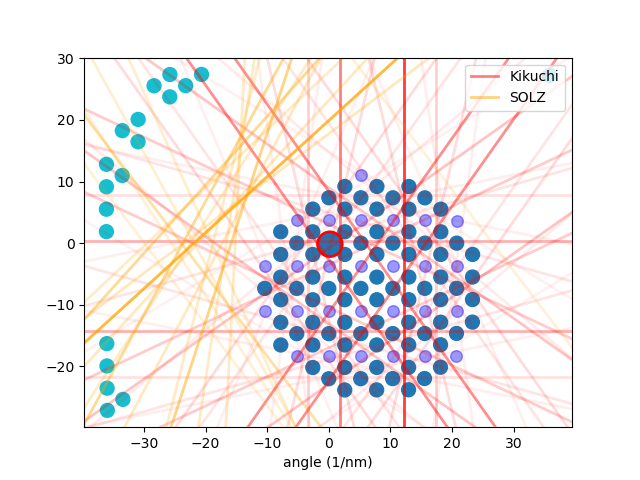

In [803]:
tags = {'acceleration_voltage': acceleration_voltage_V,
        'zone_hkl': [1, 1, -0],
        'hkl_max': 15,
        'mistilt_alpha': np.radians(1),
        'mistilt_beta': np.radians(0),
        'Sg_max': 0.03}
diff_dict = {}
diff_dict = pyTEMlib.diffraction_tools.get_bragg_reflections(atoms, tags, verbose=True) 

diff_dict.setdefault('output',{})['plot_forbidden']=False
diff_dict['output']['plot_dynamically_allowed']=True
diff_dict['output']['plot_Kikuchi']=True
diff_dict['output']['plot_HOLZ']=True
diff_dict['convergence_angle'] = 3
pyTEMlib.diffraction_tools.plot_diffraction_pattern(diff_dict, unit='1/nm')

diff_dict['HOLZ'].keys()

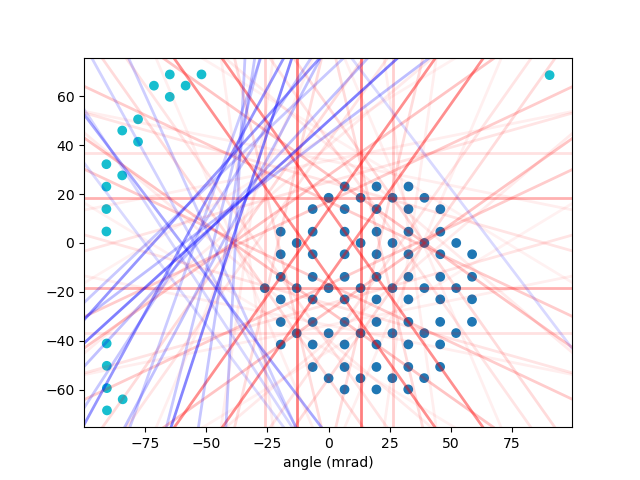

In [804]:
spots = pyTEMlib.diffraction_tools.plotting_coordinates(diff_dict['allowed']['g'])

kikuchi = pyTEMlib.diffraction_tools.plotting_coordinates(diff_dict['Kikuchi']['g'], feature='line')
holz = pyTEMlib.diffraction_tools.plotting_coordinates(diff_dict['HOLZ']['g_deficient'], feature='line')

plt.figure()
plt.scatter(spots[:,0], spots[:, 1], cmap='tab10', c=diff_dict['allowed']['Laue_Zone'])
alpha =diff_dict['Kikuchi']['intensities']/ diff_dict['Kikuchi']['intensities'].max()*.5
for i, line in enumerate(kikuchi):
    plt.axline( (line[0], line[1]), slope=line[2], color='red',
                       alpha=alpha[i], linewidth=2)
alpha =diff_dict['HOLZ']['intensities']/ diff_dict['HOLZ']['intensities'].max()*.5
for i, line in enumerate(holz):
    plt.axline( (line[0], line[1]), slope=line[2], color='blue',
                       alpha=alpha[i], linewidth=2)
plt.gca().set_aspect('equal')
plt.xlabel('angle (mrad)');


dict_keys(['g_deficient', 'g_excess', 'FOLZ', 'SOLZ', 'HOLZ_plus', 'laue_zones', 'hkl', 'intensities'])

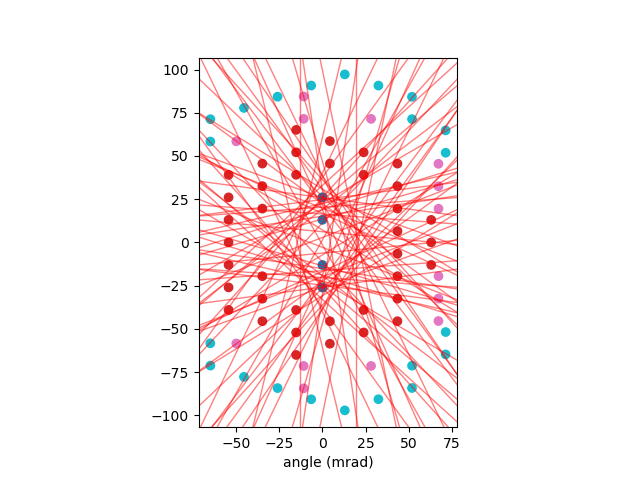

In [635]:
g_spherical1 = diff_dict['allowed']['g']
inte = diff_dict['allowed']['intensities']
x = g_spherical1[:, 0] * np.cos(g_spherical1[:, 1])*1000
y = g_spherical1[:, 0] * np.sin(g_spherical1[:, 1])*1000

k = diff_dict['Kikuchi']
k['g'] = diff_dict['HOLZ']['g_deficient']
k['laue_circle'] = [0,0]
kx = ((k['g'][:, 0] * np.cos(k['g'][:, 1]+np.pi))/2)*1000
ky = ((k['g'][:, 0] * np.sin(k['g'][:, 1]+np.pi))/2)*1000
m = np.tan((k['g'][:, 1]-np.pi/2))      

plt.figure()
plt.scatter(x, y, cmap='tab10', c=diff_dict['allowed']['Laue_Zone'])
plt.xlabel('angle (mrad)')

for i, x in enumerate(kx):
    plt.axline( (x, ky[i]), slope=m[i], color='red',
                       alpha=.5, linewidth=1)
diff_dict.keys(), diff_dict['Kikuchi']['laue_circle'], tags['mistilt_alpha']
plt.gca().set_aspect('equal')
diff_dict['HOLZ'].keys()

In [593]:
((g_spherical1[:10,0]) - (np.arcsin(g_spherical1[:10,2]/g_spherical1[:10,3])))*1000 

array([43.02786629, 45.89222924, 40.99504201, 40.05278821, 40.05278821,
       41.55483294, 40.05278821, 45.89222924, 15.3132947 , 13.05949999])

In [233]:
s = pyTEMlib.diffraction_tools.get_structure_factors(atoms, g_non_rot)
s.shape, atoms.positions, list(zip(np.round(s[200:210],3), hkl_all[200:210]))

((1330,),
 array([[0.     , 0.     , 0.     ],
        [1.35772, 1.35772, 1.35772],
        [2.71544, 2.71544, 0.     ],
        [4.07316, 4.07316, 1.35772],
        [2.71544, 0.     , 2.71544],
        [4.07316, 1.35772, 4.07316],
        [0.     , 2.71544, 2.71544],
        [1.35772, 4.07316, 4.07316]]),
 [(np.float64(0.0), array([-4.,  2., -3.])),
  (np.float64(6.863), array([-4.,  2., -2.])),
  (np.float64(0.0), array([-4.,  2., -1.])),
  (np.float64(0.0), array([-4.,  2.,  0.])),
  (np.float64(0.0), array([-4.,  2.,  1.])),
  (np.float64(6.863), array([-4.,  2.,  2.])),
  (np.float64(0.0), array([-4.,  2.,  3.])),
  (np.float64(0.0), array([-4.,  2.,  4.])),
  (np.float64(0.0), array([-4.,  2.,  5.])),
  (np.float64(0.0), array([-4.,  3., -5.]))])

In [802]:
plt.close('all')

In [220]:
g_non_rot[:100].shape

(100, 3)

In [222]:
F =  get_structure_factors(atoms, g_non_rot[:100])
F.shape, (F>0.0001).sum(), zip 

((100,),
 np.int64(26),
 array([2.52266416e-01, 1.90324689e-29, 2.65468873e-01, 1.32389370e-30,
        2.78842547e-01, 4.28245150e-31, 2.92219600e-01, 6.47544388e-30,
        3.05397735e-01, 2.03848420e-29, 3.18141974e-01, 6.30634198e-30,
        3.30189489e-01, 1.81337630e-31, 3.41257987e-01, 6.00804879e-30,
        3.51057766e-01, 8.52806732e-32, 3.59307062e-01, 5.57475538e-30,
        3.65749628e-01, 2.20899480e-32, 3.70172856e-01, 5.01886469e-30,
        3.72424299e-01, 0.00000000e+00, 3.72424299e-01, 4.37219918e-30,
        3.70172856e-01, 2.20899480e-32, 3.65749628e-01, 3.68074603e-30,
        3.59307062e-01, 8.52806732e-32, 3.51057766e-01, 2.99437138e-30,
        3.41257987e-01, 1.81337630e-31, 3.30189489e-01, 2.35598775e-30,
        3.18141974e-01, 1.97904336e-31, 3.05397735e-01, 1.35829638e-31,
        2.92219600e-01, 8.69145577e-32, 2.78842547e-01, 5.01429595e-32,
        2.65468873e-01, 2.43602942e-32, 2.52266416e-01, 1.90324689e-29,
        1.25060525e-29, 5.89053333e-31, 

In [221]:
def get_structure_factors(atoms, g_hkl):
    form_factor = np.zeros((len(atoms.positions), g_hkl.shape[0]))
    for symbol in np.unique(atoms.symbols):
        atom_positions = atoms.symbols==symbol
        form_factor[(atom_positions)] = get_form_factor(symbol, np.linalg.norm(g_hkl, axis=1))    
    structure_factors = calculate_structure_factors(np.array(g_hkl), form_factor, np.array(atoms.positions))
    return structure_factor, form_factor.sum(axis=1) 

def calculate_structure_factors(all_g, form_factor, atom_positions):
    """ Calculate structure factors for given reciprocal lattice points g_hkl"""
    structure_factors = np.zeros(len(all_g))
    form_factor_sum = np.zeros(len(all_g))
    for i, g_i in enumerate(all_g):
        struct_factor = 0.0+0.0*1j
        for j, f_j in enumerate(form_factor):
            f_q_j = f_j[i]
            r_j = atom_positions[j]
            struct_factor += f_q_j * (np.exp(-2*np.pi*1j*np.dot(g_i, r_j))).sum() 
        structure_factors[i] = (struct_factor*struct_factor.conj()).real
        form_factor_sum[i] = (form_factor[:,i]).sum()
    return structure_factors

In [34]:
pyTEMlib.diffraction_tools.form_factor('Si', g_norm), form_factor('Si', g_norm[0]), g_norm[0]

(array([0.01055248, 0.01074873, 0.01094646, ..., 0.01094646, 0.01074873,
        0.01055248], shape=(357910,)),
 array([0.01055248]),
 np.float64(11.162422713245498))

In [215]:
def get_form_factor(element, q):
    
    if isinstance(q, float):
        q = np.array([q])
    if not isinstance(q, np.ndarray):
        print('not float')
        return
    parameter_dict = pyTEMlib.crystal_tools.electronFF[element]
    f_parameter = np.array([parameter_dict[key] for key in ['fa', 'fb', 'fc', 'fd']])
    q = (np.array([q, q, q])).T
    #f =  f_lorentzian + f_gauss
    f = ((f_parameter[0]/(q**2 + f_parameter[1])).sum(axis=1) 
         + (f_parameter[2]*np.exp(-q**2 * f_parameter[3])).sum(axis=1))
    
    return f

## Load an image stack :

Please, load an image stack. <br>

A stack of images is used to reduce noise, but for an added image the images have to be aligned to compensate for drift and other microscope instabilities.

You select here (with the ``Select Main`` button,) a file of your image.

Note that the **Add** should only used for reference data

In [69]:
hkl2, g2=  pyTEMlib.diffraction_tools.get_all_reflections(atoms, 1)
g, hkl = pyTEMlib.diffraction_tools.get_all_g_vectors(1, atoms)

g[:5], g2[:5], hkl2[:5], hkl[:5]

(array([[-0.24520622, -0.24520622, -0.24520622],
        [-0.24520622, -0.24520622,  0.        ],
        [-0.24520622, -0.24520622,  0.24520622],
        [-0.24520622,  0.        , -0.24520622],
        [-0.24520622,  0.        ,  0.        ]]),
 array([[ 0.        ,  0.        , -0.24520622],
        [ 0.        ,  0.24520622,  0.        ],
        [-0.24520622,  0.        ,  0.        ],
        [ 0.        ,  0.        ,  0.24520622],
        [ 0.24520622,  0.        ,  0.        ]]),
 array([[ 0.,  0., -1.],
        [ 0.,  1.,  0.],
        [-1.,  0.,  0.],
        [ 0.,  0.,  1.],
        [ 1.,  0.,  0.]]),
 array([[-1., -1., -1.],
        [-1., -1.,  0.],
        [-1., -1.,  1.],
        [-1.,  0., -1.],
        [-1.,  0.,  0.]]))

In [58]:
fileWidget = pyTEMlib.file_tools.FileWidget()


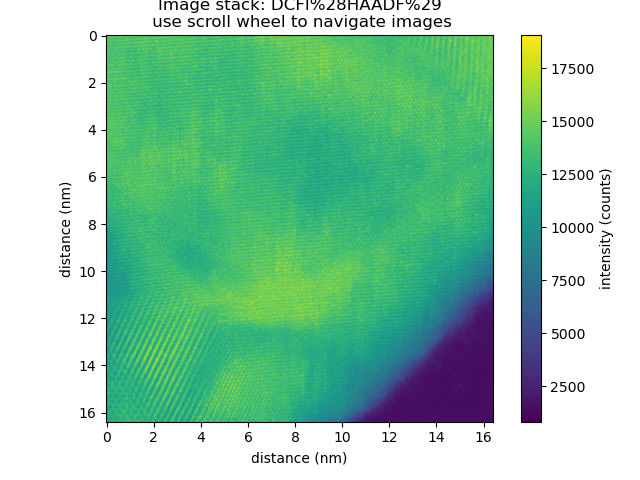

In [94]:
image = fileWidget.selected_dataset
view = image.plot()

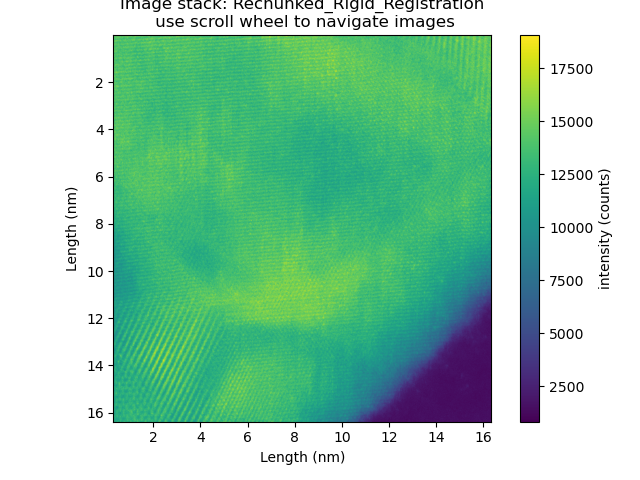

In [89]:
rigid_registered = pyTEMlib.image_tools.rigid_registration(image)
v= rigid_registered.plot()

In [44]:
image2 = rigid_registered[:, 300:-212, 512:].sum(axis=0)
image2 -= image2.max()/2
image2[image2<0] = 0.
image2.data_type='image'
v = image2.plot()

NameError: name 'rigid_registered' is not defined

In [43]:
fft_image = pyTEMlib.image_tools.power_spectrum(image2)

v = fft_image.plot()
#, diffractogram_spots

NameError: name 'image2' is not defined

In [174]:
spots = pyTEMlib.image_tools.diffractogram_spots(fft_image, 0.05)[0]
plt.scatter(spots[:, 0], spots[:,1], c='r')

In [175]:
angles = np.degrees(np.atan2(spots[1:, 1],spots[1:, 0]))

angles = angles-angles.min()- 180
angles, np.linalg.norm(spots[1:, :2],axis=1)

(array([-1.51791087e+02,  2.82089131e+01,  1.53127322e+02, -2.68726778e+01,
        -1.16872678e+02,  6.31273222e+01, -1.20141646e+02,  5.98583541e+01,
        -6.24845317e+01,  1.17515468e+02,  2.84217094e-14, -1.80000000e+02,
        -2.68726778e+01,  1.53127322e+02,  6.31273222e+01, -1.16872678e+02,
        -2.68726778e+01,  1.53127322e+02, -1.16872678e+02,  6.31273222e+01,
         6.31273222e+01, -1.16872678e+02,  1.53127322e+02, -2.68726778e+01,
        -1.16872678e+02,  6.31273222e+01,  1.53127322e+02, -2.68726778e+01,
        -1.16872678e+02,  6.31273222e+01, -2.68726778e+01,  1.53127322e+02,
        -1.16872678e+02,  6.31273222e+01,  1.53127322e+02, -2.68726778e+01,
        -1.16872678e+02,  6.31273222e+01, -2.68726778e+01,  1.53127322e+02,
        -1.16872678e+02,  6.31273222e+01, -2.68726778e+01]),
 array([ 4.02421292,  4.02421292,  4.09510602,  4.09510602,  4.27742238,
         4.27742238,  6.73261874,  6.73261874,  6.92608507,  6.92608507,
         7.02975163,  7.02975163,

In [151]:
6.90524432/ 6.81851881

1.0127191128185802

TypeError: scatter() missing 1 required positional argument: 'y'

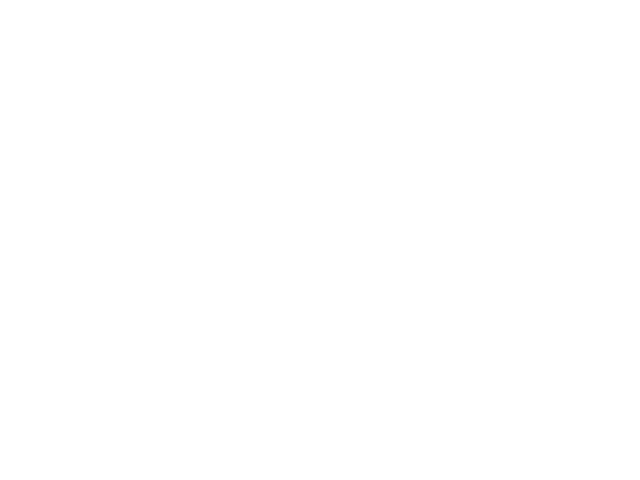

In [164]:
plt.figure()
plt.scatter(angles, r = [6.92]*len(angles)) #np.linalg.norm(spots[1:, :2],axis=1))

mistilt
Of the 90 possible reflection 23 are allowed.
Of those, there are 18 in ZOLZ  and 5 in HOLZ
Of the 47 forbidden reflection in ZOLZ  0 can be dynamically activated.


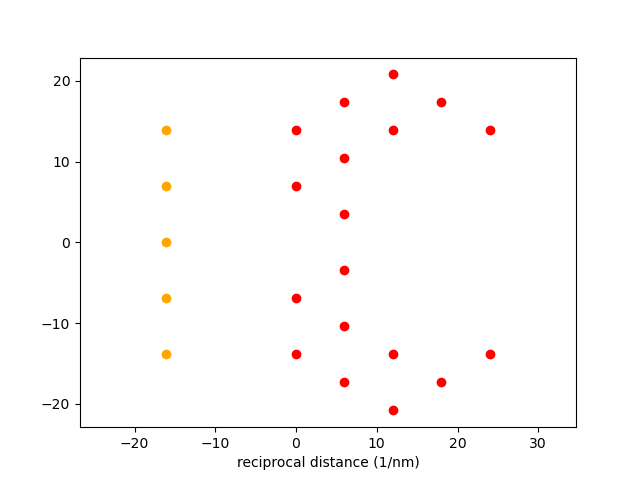

In [6]:
# --------------- INPUT ------------------------
structure = 'gold'
zone_hkl = np.array([1, 1, 1])
hkl_max = 8 #  maximum allowed Miller index
sg_max = 0.03   # 1/Ang  maximum allowed excitation error

acceleration_voltage = 200.0 * 1000.0 #V

rotation = np.radians(0)  # rotation of diffraction pattern
# -------------------------------------------
atoms = pyTEMlib.crystal_tools.structure_by_name(structure)
tags = {'zone_hkl': zone_hkl,
        'hkl_max': hkl_max,
        'Sg_max': sg_max,
        'mistilt_alpha': np.radians(3),
        'acceleration_voltage':  acceleration_voltage}

diff_dict ={}
diff_dict = pyTEMlib.diffraction_tools.get_bragg_reflections(atoms, tags, verbose=True) 

# Simple Plot
ZOLZ = diff_dict['allowed']['ZOLZ']
HOLZ = diff_dict['allowed']['HOLZ']
r = diff_dict['allowed']['g'][:, 0]
phi = diff_dict['allowed']['g'][:, 1]

x = r *np.cos(phi+rotation)*10
y = r * np.sin(phi+rotation)*10


plt.figure()
plt.scatter(x[ZOLZ], y[ZOLZ], label='ZOLZ allowed', c='r')
plt.scatter(x[HOLZ], y[HOLZ], label="HOLZ allowed", c ='orange')
plt.axis('equal')
plt.xlabel('reciprocal distance (1/nm)');


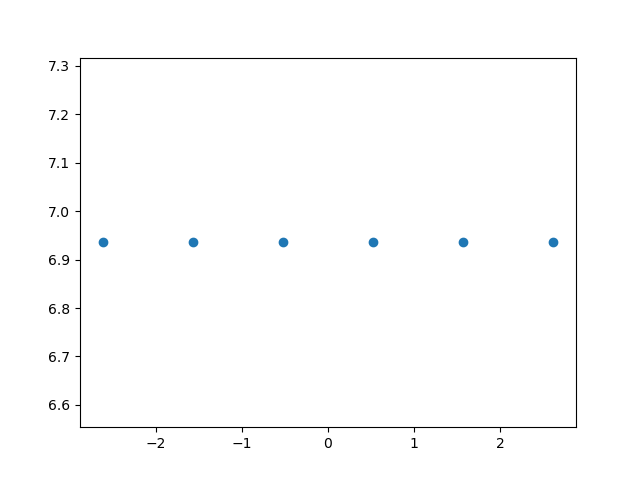

In [42]:
plt.figure()
plt.scatter(phi, r*10)

In [182]:
# -----Input for ring pattern calculation ----
structure = 'gold'
hkl_max = 15
verbose = True
# --------------------------------------------

atoms = pyTEMlib.crystal_tools.structure_by_name(structure)
image2.structures['Structure_000'] = atoms
image2.metadata['experiment']['hkl_max']  = hkl_max

pyTEMlib.diffraction_tools.ring_pattern_calculation(image2, verbose=verbose)



Of the 29790 possible reflection 7470 are allowed.
here
Of the 7470 allowed reflection 153  have unique distances.


 [hkl]  	 1/d [1/nm] 	 d [nm] 	 F^2 
[1. 1. 1.] 	 4.25 	         0.2355 	 729.11 
[0. 0. 2.] 	 4.90 	         0.2039 	 599.47 
[2. 0. 2.] 	 6.94 	         0.1442 	 333.71 
[1. 1. 3.] 	 8.13 	         0.1230 	 241.36 
[2. 2. 2.] 	 8.49 	         0.1177 	 219.62 
[0. 4. 0.] 	 9.81 	         0.1020 	 158.02 
[3. 3. 1.] 	 10.69 	         0.0936 	 128.30 
[4. 2. 0.] 	 10.97 	         0.0912 	 120.38 
[4. 2. 2.] 	 12.01 	         0.0832 	 95.48 
[3. 3. 3.] 	 12.74 	         0.0785 	 81.88 
[4. 4. 0.] 	 13.87 	         0.0721 	 65.29 
[5. 1. 3.] 	 14.51 	         0.0689 	 57.83 
[2. 4. 4.] 	 14.71 	         0.0680 	 55.65 
[2. 0. 6.] 	 15.51 	         0.0645 	 48.14 
[3. 3. 5.] 	 16.08 	         0.0622 	 43.55 
[2. 2. 6.] 	 16.27 	         0.0615 	 42.17 
[4. 4. 4.] 	 16.99 	         0.0589 	 37.33 
[1. 5. 5.] 	 17.51 	         0.0571 	 34.26 
[6. 0. 4.] 	 17.68 	         0.056

(np.float64(17732.5),
 np.float64(311975.0),
 np.float64(25086.0),
 np.float64(155987.5),
 np.float64(0.0))

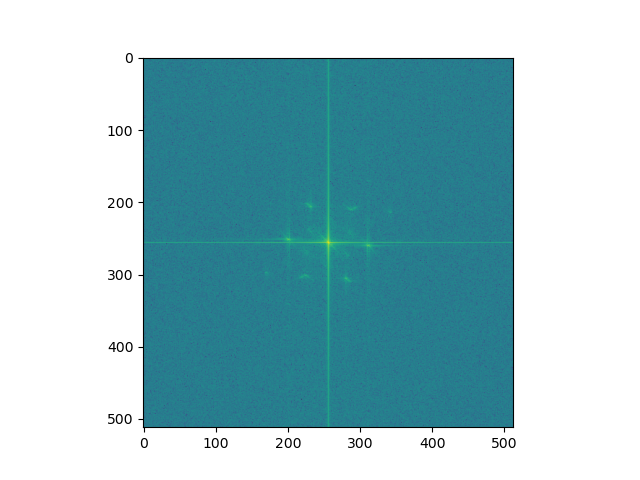

In [59]:
image3 = np.array(image2)-(image2.max()/2)
image3 [image3<0.] =0
im2 = np.fft.fftshift(np.fft.fft2(image3))
plt.close('all')
plt.figure()
plt.imshow(np.log(1+np.abs(im2)))
#plt.imshow(image3)
image3[346,263], image2.max(), image2.min(), image3.max(), image3.min()

In [15]:
chooser.dataset

sidpy.Dataset of type SPECTRAL_IMAGE with:
 dask.array<array, shape=(215, 178, 2048), dtype=uint16, chunksize=(215, 178, 2048), chunktype=numpy.ndarray>
 data contains: intensity (counts)
 and Dimensions: 
x:  distance (nm) of size (215,)
y:  distance (nm) of size (178,)
energy_scale:  energy (eV) of size (2048,)
 with metadata: ['experiment', 'EDS']

In [21]:
dataset = chooSer.dataset
dataset

sidpy.Dataset of type UNKNOWN with:
 dask.array<array, shape=(2471962, 1), dtype=uint16, chunksize=(2471962, 1), chunktype=numpy.ndarray>
 data contains: generic (generic)
 and Dimensions: 
a:  generic (generic) of size (2471962,)
b:  generic (generic) of size (1,)
 with metadata: ['experiment', 'EDS']

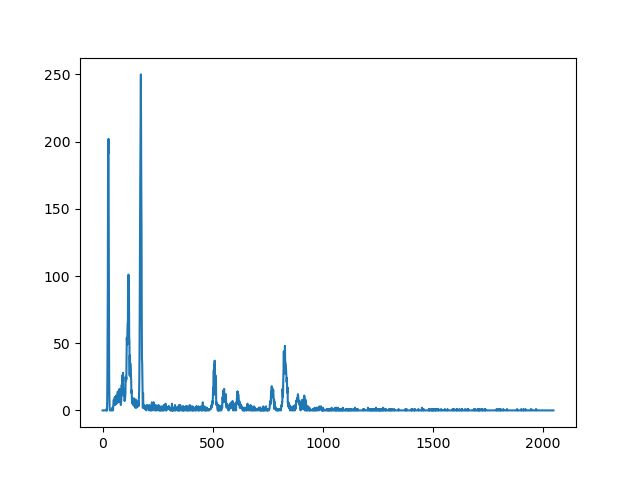

In [62]:
dataset = np.array(chooser.dataset).squeeze()
pixels = np.where(dataset==65535)[0]
frames = np.where(pixels%(215*178)==0)[0]
pixel_frames = np.searchsorted(pixels,frames)

spectra = np.zeros([215*178,2048]) 

def get_spectra(dataset, start, end):
    spectra = np.zeros([end-start, 2048]) 
    for frame in pixel_frames:
        last_pixel = pixels[frame+start]
        for index,  next_pixel in enumerate(pixels[frame+start:frame+end]):
            for pixel in range(last_pixel+1, next_pixel):
                spectra[index, int(dataset[pixel]/2)] += 1
            last_pixel = next_pixel

    return spectra
spectra = get_spectra(dataset, int(215*178/8), int(215*178/4))
plt.figure()
plt.plot(spectra.sum(axis=0))

In [61]:
pixels = np.where(np.array(dataset)==65535)[0]
print(pixels.shape[0]-dataset.shape[0])
frames = pixels[(215*178) *np.arange(63)]
print(frames)

spectra = np.zeros([215*178,2048]) 
for frame in frames[60:-1]:
    for i in range(40):
        for j in range(pixels[i+frame],pixels[i+1+frame]):
            #print(i, j, data[j])
            if data[j] < 65535:
                spectra[i, int(data[j]/2)] += 1
plt.figure()
plt.plot(spectra[:10000].sum(axis=0))

-60952
[      0   39338   78669  117989  157237  196576  235894  275245  314578
  353860  393154  432446  471759  511116  550399  589665  628940  668152
  707381  746598  785861  825122  864417  903674  942946  982206 1021462
 1060746 1099981 1139199 1178445 1217647 1256918 1296153 1335367 1374617
 1413836 1453061 1492242 1531462 1570657 1609873 1649126 1688291 1727463
 1766701 1805889 1845093 1884299 1923506 1962751 2001969 2041178 2080387
 2119505 2158702 2197869 2237021 2276166 2315345 2354514 2393669 2432796]


KeyError: 2414189

In [122]:
38282, 215*178

(38282, 38270)

In [51]:
fileWidget.file_name
datasets = pyTEMlib.file_tools.open_file(fileWidget.file_name, eds_stream=True)
selector = sidpy.ChooseDataset(datasets)

{'Detector-0': {'DetectorName': 'BF-S', 'DetectorType': 'ScanningDetector', 'Inserted': 'false', 'Enabled': 'true', 'Gain': '51', 'Offset': '0', 'CollectionAngleRange': {'begin': '0', 'end': '0'}}, 'Detector-1': {'DetectorName': 'BM-Ceta', 'DetectorType': 'ImagingDetector', 'ExposureMode': '', 'Binning': {'width': '1', 'height': '1'}, 'ReadOutArea': {'left': '0', 'top': '0', 'right': '4096', 'bottom': '4096'}, 'ExposureTime': '0.5', 'Shutters': {'Shutter-0': {'Position': 'PostSpecimen', 'Type': 'Electrostatic'}}, 'DarkGainCorrectionType': '2'}, 'Detector-2': {'DetectorName': 'DF-S', 'DetectorType': 'ScanningDetector', 'Inserted': 'false', 'Enabled': 'true', 'Gain': '39.371789999999997', 'Offset': '-2.4570908548628407e-09', 'CollectionAngleRange': {'begin': '0', 'end': '0'}}, 'Detector-3': {'DetectorName': 'EF-CCD', 'DetectorType': 'ImagingDetector', 'ExposureMode': '', 'Binning': {'width': '1', 'height': '1'}, 'ReadOutArea': {'left': '0', 'top': '0', 'right': '4096', 'bottom': '4096'},

Dropdown(description='select dataset:', options=('Channel_000: Mn', 'Channel_001: Mg', 'Channel_002: Ni', 'Cha…

In [77]:
dataset = selector.datasetsqueeze()
pixels = np.where(dataset==65535)[0]
frames = np.where(pixels%(215*178)==0)

frames
selector.dataset.squeeze().shape

for 

(2466020,)

1.0

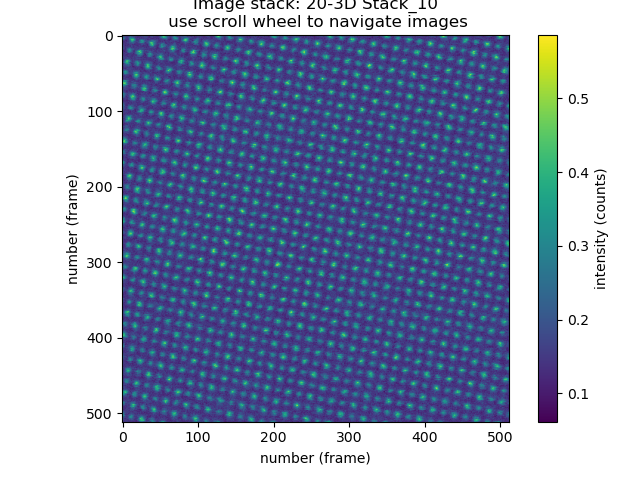

In [5]:
dataset = selector.dataset
dataset.data_type = 'IMAGE_STACK'
dataset.x.dimension_type = 'SPATIAL'
dataset.y.dimension_type = 'SPATIAL'

view = dataset.plot()
dataset.x.slope


Some of the metadata is available in the ``metadata`` attribute of the dataset but all information can be found in ``original metadata``.

## Complete Registration 

Takes a while, depending on your computer between 1 and 10 minutes

### Rigid Registration

Using sub-pixel accuracy registration determination method of:

Manuel Guizar-Sicairos, Samuel T. Thurman, and James R. Fienup, “Efficient subpixel image registration algorithms,” Optics Letters 33, 156-158 (2008). [DOI:10.1364/OL.33.000156](https://www.doi.org/%2010.1364/OL.33.000156)

as implemented in ``phase_cross_correlation`` function by ``scikit-image`` in the [registration](https://scikit-image.org/docs/dev/api/skimage.registration.html) package. 

### Non-Rigid Registration

Here we use the **Diffeomorphic Demon Non-Rigid Registration** as provided by **simpleITK**.  

Please Cite: 
* [simpleITK](http://www.simpleitk.org/SimpleITK/project/parti.html)
    
    and
    
* [T. Vercauteren, X. Pennec, A. Perchant and N. Ayache *Diffeomorphic Demons Using ITK\'s Finite Difference Solver Hierarchy* The Insight Journal, 2007](http://hdl.handle.net/1926/510)

Stack contains  25  images, each with 512  pixels in x-direction and  512  pixels in y-direction


  0%|          | 0/25 [00:00<?, ?it/s]

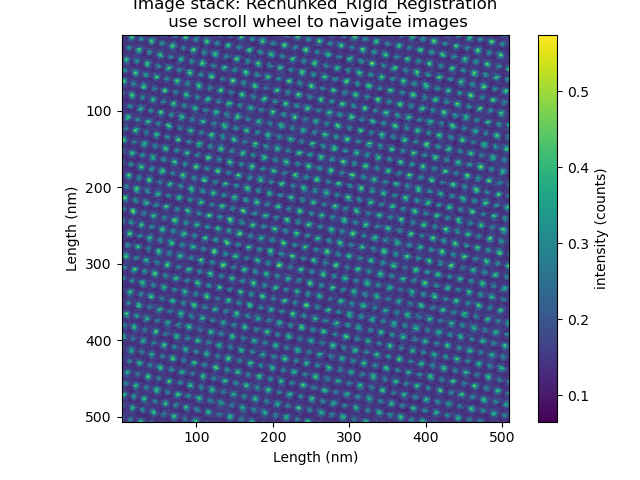

In [6]:
rigid_registered= pyTEMlib.image_tools.rigid_registration(dataset)
datasets['rigid_registered'] = rigid_registeredrigid_registered
view = rigid_registered.plot()

  0%|          | 0/25 [00:00<?, ?it/s]

:-)
You have successfully completed Diffeomorphic Demons Registration


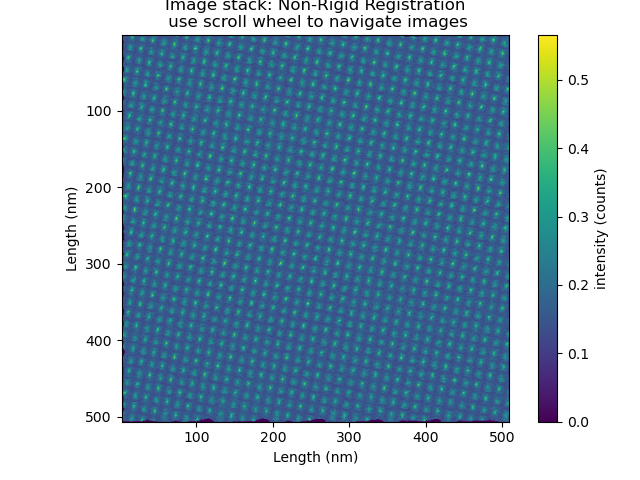

In [7]:
demon_registered = pyTEMlib.image_tools.demon_registration(rigid_registered)
datasets['demon_registered'] = demon_registered
view2 = demon_registered.plot()

Or do it all together

In [ ]:
import importlib
importlib.reload(pyTEMlib.image_tools)

demon_registered, rigid_registered = pyTEMlib.image_tools.complete_registration(dataset)
demon_registered.data_type = 'image_stack'
view2 = demon_registered.plot()

You will need to zoom in to see that the images are changing.

Compare this to the rigid registered stack

In [ ]:
Save these datasets


In [18]:
pyTEMlib.file_tools.save(FileWidget.filename{:-3] +'hdf5')


'C:\\Users\\gduscher\\Downloads\\0047 - 20250226 4.30 Mx STEM HAADF Diffraction 23.2 nm.'

### Check Drift

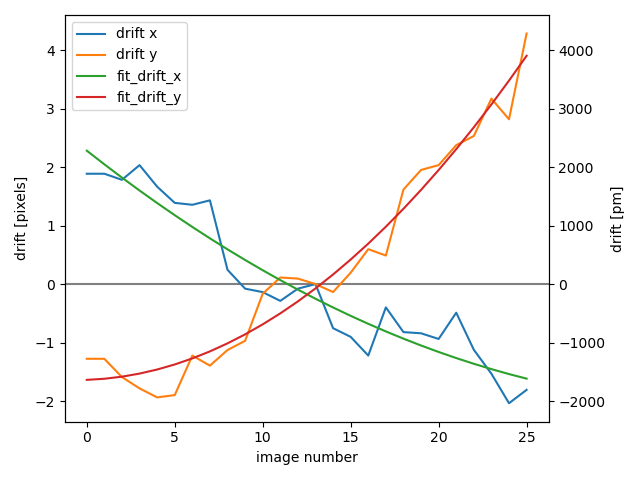

In [8]:
drift = rigid_registered.metadata['drift']
polynom_degree = 2 # 1 is linear fit, 2 is parabolic fit, ...

x = np.linspace(0,drift.shape[0]-1,drift.shape[0])

line_fit_x = np.polyfit(x, drift[:,0], polynom_degree)
poly_x = np.poly1d(line_fit_x)
line_fit_y = np.polyfit(x, drift[:,1], polynom_degree)
poly_y = np.poly1d(line_fit_y)

plt.figure()
plt.axhline(color = 'gray')
plt.plot(x, drift[:,0], label = 'drift x')
plt.plot(x, drift[:,1], label = 'drift y')
plt.plot(x, poly_x(x),  label = 'fit_drift_x')
plt.plot(x, poly_y(x),  label = 'fit_drift_y')

plt.legend();
ax_pixels = plt.gca()
ax_pixels.step(1, 1)

scaleX = 1000 #(rigid_registered.x[1]-rigid_registered.x[0])*1000.  #in pm

ax_pm = ax_pixels.twinx()
x_1, x_2 = ax_pixels.get_ylim()

ax_pm.set_ylim(x_1*scaleX, x_2*scaleX)

ax_pixels.set_ylabel('drift [pixels]')
ax_pm.set_ylabel('drift [pm]')
ax_pixels.set_xlabel('image number');
plt.tight_layout()


## Find Atom Positions
### Lucy -Richardson Deconvolution

Lucy - Richardson Deconvolution removes noise and convolutes the intensity back into the atom (columns).

Here we use a slightly modified Lucy - Richardson Deconvolution which stops when converged.

Ideally the atom_size should be as large as the atoms in the image.

A good Lucy-Richardson Deconvolution should result in an image with atoms of a radius of about 2 pixels.

The number of steps to convergence should be less than 300 for a good approximation of atom_size.
> we use the non-rigid registered datset


In [62]:
# ------- Input ------
atoms_size = .06 # in nm
# --------------------

# image = demon_registered.sum(axis=0)
# image = dataset.sum(axis=0)

out_tags = {}
image.metadata['experiment']= {'convergence_angle': 30, 'acceleration_voltage': 200000.}

scale_x =image.x.slope
gauss_diameter = atoms_size/scale_x
print(gauss_diameter)
if gauss_diameter < 3:
    print('smal')
    gauss_diameter = 3
print(gauss_diameter, gauss_diameter*scale_x)
gauss_probe = pyTEMlib.probe_tools.make_gauss(image.shape[0], image.shape[1], gauss_diameter)

print('Deconvolution of ', dataset.title)
LR_dataset = pyTEMlib.image_tools.decon_lr(image, gauss_probe, verbose=False)

extent = LR_dataset.get_extent([0,1])
fig, ax = plt.subplots(1, 2, figsize=(8, 4), sharex=True, sharey=True)
ax[0].imshow(image.T, extent = extent,vmax=np.median(np.array(image))+3*np.std(np.array(image)))
ax[1].imshow(LR_dataset.T, extent = extent, vmax=np.median(np.array(LR_dataset))+3*np.std(np.array(LR_dataset)));

datasets['lr_decon'] = LR_dataset

3.7470220056147725
3.7470220056147725 0.06
Deconvolution of 


AttributeError: 'numpy.ndarray' object has no attribute 'get_image_dims'

#### Log Deconvolution

In [89]:
LR_dataset.metadata.update({'analysis': {'Lucy_Richardson': {
                        'notebook': 'Image_Registration' ,
                        # 'notebook_version': __notebook_version__,
                        'input': dataset.title,
                        'probe_diameter': gauss_diameter,
                        'kind_of_probe': 'Gauss',
                        'probe_width': atoms_size
                        }}})
LR_dataset.metadata

{'analysis': {'Lucy_Richardson': {'notebook': 'Image_Registration',
   'input': '20-3D Stack_10',
   'probe_diameter': 3,
   'kind_of_probe': 'Gauss',
   'probe_width': 0.06}},
 'experiment': {'convergence_angle': 30,
  'acceleration_voltage': 200000.0,
  'wavelength': 0.0025079340436272276},
 'input_crop': [3, 509, 2, 507],
 'input_shape': (512, 25),
 'input_dataset': '20-3D Stack_10'}

### Atom Detection with Blob-Finder

Choose threshold and atom size so that all atoms or at least all bright atoms of an unit cell are found 

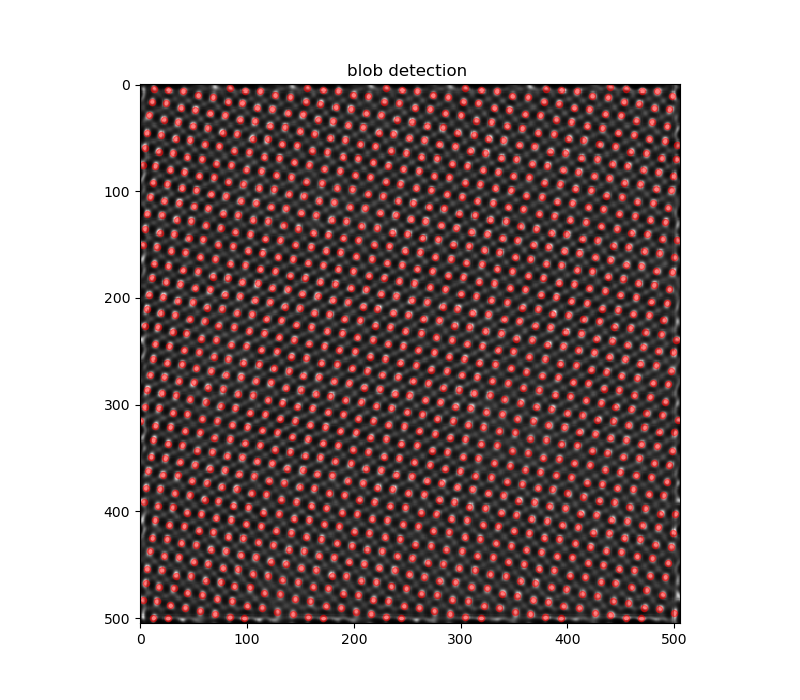

In [17]:
import skimage
# ------- Input ------
threshold = 20.7 #usally between 0.01 and 0.9  the smaller the more atoms
atom_size = .05 #in nm  
# ----------------------


image = LR_dataset
#image = image_choice.dataset
# scale_x = pyTEMlib.file_tools.get_slope(image.dim_1)
blobs =  skimage.feature.blob_log(image, max_sigma=atom_size/scale_x, threshold=threshold)

fig1, ax = plt.subplots(1, 1,figsize=(8,7), sharex=True, sharey=True)
plt.title("blob detection ")

plt.imshow(image.T, interpolation='nearest',cmap='gray', vmax=np.median(np.array(image))+3*np.std(np.array(image)))
plt.scatter(blobs[:, 0], blobs[:, 1], c='r', s=20, alpha = .5);

#### Log Atom Positions

In [94]:
out_tags  =  {}
out_tags['analysis']= 'Atom Positions'
# out_tags['notebook']= __notebook__ 
# out_tags['notebook_version']= __notebook_version__

out_tags['atoms'] = blobs
out_tags['atom_size'] = atom_size #in nm gives the size of the atoms or resolution
out_tags['threshold'] =  threshold  #between 0.01 and 0.1 
out_tags['pixel_size'] = scale_x


out_tags['name'] = 'Atom finding'
out_tags['title'] = out_tags['name']
tags = {'atom_pixel':  out_tags}
if isinstance(image.metadata['analysis'], str):
    image.metadata['analysis']={image.metadata['analysis']:{}}

image.metadata['analysis'].update(tags)

image.metadata['analysis']

{'non-rigid demon registration': {},
 'atom_pixel': {'analysis': 'Atom Positions',
  'atoms': array([[6.0000000e+00, 4.5000000e+01, 5.0000001e-02],
         [6.0000000e+00, 1.2100000e+02, 5.0000001e-02],
         [4.9800000e+02, 1.1000000e+01, 5.0000001e-02],
         ...,
         [5.0300000e+02, 1.4600000e+02, 5.0000001e-02],
         [4.4000000e+02, 2.0000000e+00, 1.5555555e-01],
         [5.0300000e+02, 5.7000000e+01, 5.0000001e-02]], dtype=float32),
  'atom_size': 0.05,
  'threshold': 20.7,
  'pixel_size': 1,
  'name': 'Atom finding',
  'title': 'Atom finding'}}

### Refine All Atom Positions
Fitting of a Gaussian into the center of an atom

There will be convergence errors if the atom_radius value is too large or too small

In [22]:
image_choice = sidpy.ChooseDataset(datasets)  

Dropdown(description='select dataset:', options=('Channel_000: 20-3D Stack_10', 'rigid_registered: Rechunked_R…

sidpy.Dataset of type IMAGE_STACK with:
 dask.array<sub, shape=(506, 505), dtype=float64, chunksize=(506, 505), chunktype=numpy.ndarray>
 data contains: intensity (counts)
 and Dimensions: 
x:  Length (nm) of size (506,)
y:  Length (nm) of size (505,)
 with metadata: ['analysis', 'experiment', 'input_crop', 'input_shape', 'input_dataset']
using radius  3 pixels


  0%|          | 0/1183 [00:00<?, ?it/s]

C:\Users\gduscher\OneDrive - University of Tennessee\GitHub\Image_Distortion\../pyTEMlib\pyTEMlib\probe_tools.py:17: RuntimeWarning: invalid value encountered in divide
  probe = g / g.sum() * intensity


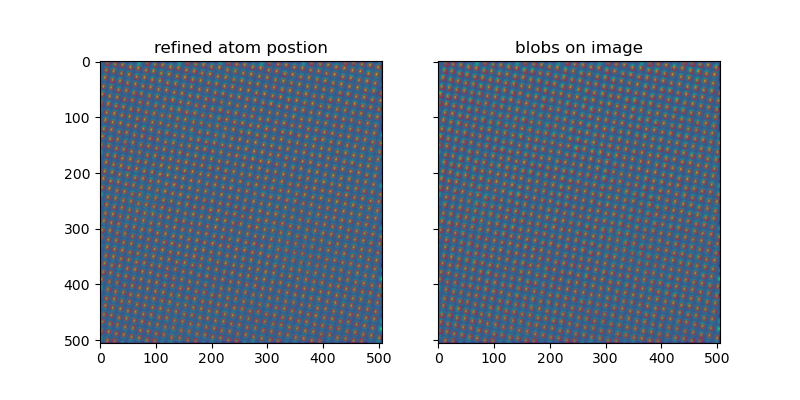

In [79]:
# ------- Input ------
atom_radius = 3  # in pixel
# ----------------------

if image_choice.dataset.data_type.name == 'IMAGE_STACK':
    image = image_choice.dataset.sum(axis=0)
else:
    image = image_choice.dataset

#atoms = atom_group['atoms'][()]
atoms = blobs
image = image-image.min()
print(image)

#atom_radius = 2
MaxInt = 0
MinInt = 0 
maxDist = 2
sym = pyTEMlib.atom_tools.atom_refine(np.array(image), atoms, atom_radius, max_int = 0, min_int = 0, max_dist = 2)
refined_atoms = np.array(sym['atoms'])

fig, ax = plt.subplots(1, 2, figsize=(8, 4), sharex=True, sharey=True)
ax[0].imshow(image.T)
ax[0].scatter(refined_atoms[:,0],refined_atoms[:,1],  s=10, alpha = 0.3, color = 'red')
ax[0].set_title('refined atom postion')
ax[1].imshow(image.T)
ax[1].scatter(atoms[:, 0], atoms[:, 1], c='r', s=10, alpha = .3);
ax[1].set_title('blobs on image');

#### Log Refined Atom Positions

In [ ]:
out_tags  =  {}
out_tags['analysis']= 'Atom Positions'
# out_tags['notebook']= __notebook__ 
# out_tags['notebook_version']= __notebook_version__

out_tags['atoms'] = blobs
out_tags['atom_size'] = atom_size #in nm gives the size of the atoms or resolution
out_tags['threshold'] =  threshold  #between 0.01 and 0.1 
out_tags['pixel_size'] = scale_x


out_tags['name'] = 'Atom finding'
out_tags['title'] = out_tags['name']
tags = {'atom_pixel':  out_tags}
if isinstance(image.metadata['analysis'], str):
    image.metadata['analysis']={image.metadata['analysis']:{}}

image.metadata['analysis'].update(tags)

image.metadata['analysis']

## Analyse Atom Position
### Find angles of all unit cells

### Define Crystal and Zone-Axis

In [141]:
crystal_name = 'Au'
crystal = pyTEMlib.crystal_tools.structure_by_name(crystal_name)
print(crystal_name)
crystal

crystal.cell.lengths()[0]/image.x.slope/10
crystal.info = {'experimental': {'zone_axis': [1, 1, 1], 'angle': 0}}
layer = pyTEMlib.crystal_tools.get_projection(crystal)
gamma =  layer.cell.angles()[2]
layer.cell.lengths() , layer.cell.lengths()/image.x.slope/10 , layer.cell.angles(), np.linalg.norm(layer.positions[:,:2], axis=1), layer.get_scaled_positions()

Au
projected atomic numbers


(array([5.76744575e+00, 5.76744575e+00, 1.11022302e-16]),
 array([3.60179102e+01, 3.60179102e+01, 6.93338351e-16]),
 array([90., 90., 60.]),
 array([0.        , 2.88372288, 2.88372288, 4.99475453]),
 array([[ 0.00000000e+00,  0.00000000e+00, -1.16901319e-02],
        [ 0.00000000e+00,  5.00000000e-01,  5.00000000e-01],
        [ 5.00000000e-01,  1.08088567e-17,  5.00000000e-01],
        [ 5.00000000e-01,  5.00000000e-01,  1.01169013e+00]]))

CPU times: total: 1.48 s
Wall time: 1.59 s


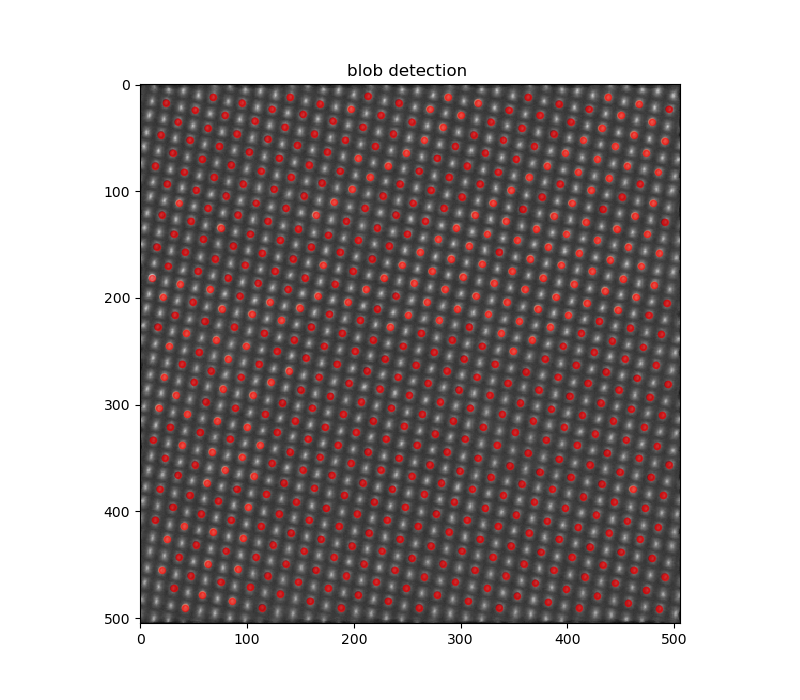

In [23]:
import scipy
import pyTEMlib.graph_tools
def breath_first(graph, initial, lattice_parameter, tolerance=1):
    
    neighbour_tree = scipy.spatial.KDTree(graph)
    distances, indices = neighbour_tree.query(graph,  # let's get all neighbours
                                              k=50)  # projection_tags['number_of_nearest_neighbours']*2 + 1)
    visited = []  # the atoms we visited
    angles = []  # atoms at ideal lattice
    sub_lattice = []
    sub_lattice = []  # atoms in base and disregarded
    queue = [initial]
    queue_angles=[0]
    
    while queue:
        node = queue.pop(0)
        angle = queue_angles.pop(0)
        
        if node not in visited and node not in sub_lattice:
            visited.append(node)
            angles.append(angle)
            neighbors = indices[node]
            for i, neighbour in enumerate(neighbors):
                if neighbour not in visited:
                    hopp = graph[node] - graph[neighbour]
                    distance_to_ideal = np.linalg.norm(hopp)
                    if distance_to_ideal < lattice_parameter - tolerance*5:
                        sub_lattice.append(neighbour) 
                    elif np.min(np.abs(distance_to_ideal- lattice_parameter)) < tolerance:
                        queue.append(neighbour) 
                        queue_angles.append(np.arctan2(hopp[1], hopp[0]))
    angles[0] = angles[1]
    out_atoms = np.stack([graph[visited][:, 0], graph[visited][:, 1], angles])
    return out_atoms.T, visited

def delete_rim_atoms(atoms, extent, rim_distance):
    rim = np.where(atoms[:, :2] - extent > -rim_distance)[0]
    middle_atoms = np.delete(atoms, rim, axis=0)
    rim = np.where(middle_atoms[:, :2].min(axis=1)<rim_distance)[0]
    middle_atoms = np.delete(middle_atoms, rim, axis=0)
    return middle_atoms
init = 633
#init = 6328
#init= 6589

%time hopped_atoms, indices = breath_first(blobs, init, 22, 2)
middle_atoms = pyTEMlib.graph_tools.delete_rim_atoms(hopped_atoms, image.shape, 10)

plt.close('all')
fig1, ax = plt.subplots(1, 1,figsize=(8,7), sharex=True, sharey=True)
plt.title("blob detection ")

plt.imshow(demon_registered.sum(axis=0).T, interpolation='nearest',cmap='gray', vmax=np.median(np.array(image))+3*np.std(np.array(image)))
plt.scatter(middle_atoms[:, 0], middle_atoms[:, 1], c=np.degrees(np.degrees(middle_atoms[:, 2])% 60), cmap = 'Reds', s=20, alpha = .5);
plt.scatter(middle_atoms[:, 0], middle_atoms[:, 1], c='red', s=20, alpha = .5);
#plt.scatter(blobs[init][0], blobs[init][1], c='orange')
angles = np.degrees(middle_atoms[:, 2])% 60


In [80]:
crystal_name = 'SrTiO3'
crystal = pyTEMlib.crystal_tools.structure_by_name(crystal_name)
print(crystal_name)
crystal

crystal.cell.lengths()[0]/image.x.slope/10
crystal.info = {'experimental': {'zone_axis': [0, 0, 1], 'angle': 0}}
layer = pyTEMlib.crystal_tools.get_projection(crystal)
print(layer.cell.angles())
gamma =  layer.cell.angles()[2]
layer.cell.lengths() , layer.cell.lengths()/image.x.slope/10 , layer.cell.angles(), np.linalg.norm(layer.positions[:,:2], axis=1), layer.get_scaled_positions()

SrTiO3
projected atomic numbers
[90. 90. 90.]


(array([3.905268, 3.905268, 1.952634]),
 array([0.3905268, 0.3905268, 0.1952634]),
 array([90., 90., 90.]),
 array([0.        , 2.76144149, 2.76144149, 1.952634  , 1.952634  ]),
 array([[0. , 0. , 0. ],
        [0.5, 0.5, 1. ],
        [0.5, 0.5, 0. ],
        [0. , 0.5, 1. ],
        [0.5, 0. , 1. ]]))

### Analyse Angles of Unit Cells

1183
 Average unit cell angle 56.2 with standard deviation 1.55; from 50.9 to 60.9


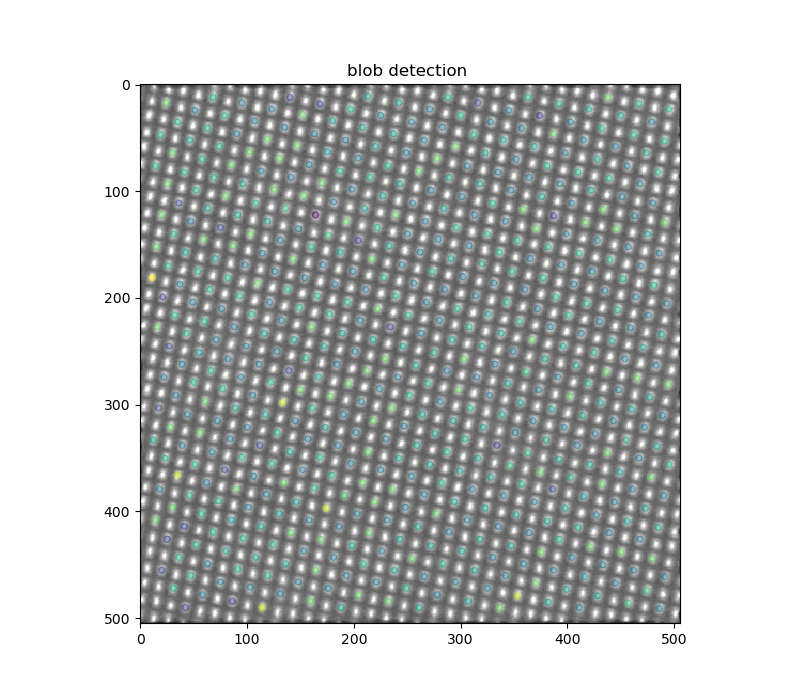

In [81]:
print(len(blobs))
fig1, ax = plt.subplots(1, 1,figsize=(8,7), sharex=True, sharey=True)
plt.title("blob detection ")

plt.imshow(image.T, interpolation='nearest',cmap='gray', vmax=np.median(np.array(image))+3*np.std(np.array(image)))
plt.scatter(middle_atoms[:, 0], middle_atoms[:, 1], c=np.degrees(np.degrees(middle_atoms[:, 2])% gamma), cmap = 'viridis', s=20, alpha = .5);
angles = np.degrees(middle_atoms[:, 2])% gamma

print(f' Average unit cell angle {np.average(angles):.1f} with standard deviation {np.std(angles):.2f}; from {np.min(angles):.1f} to {np.max(angles):.1f}')

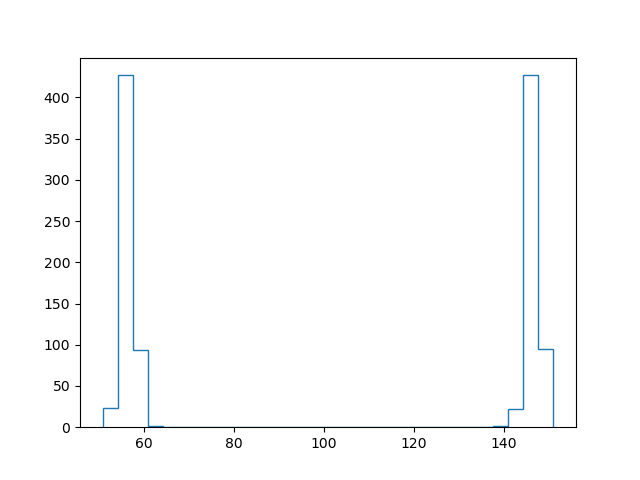

In [82]:
plt.figure()
plot_angles = np.append(angles, angles+gamma)
plot_angles[plot_angles<0] +=gamma 
counts, bins = np.histogram(plot_angles, bins = 30)
plt.stairs(counts, bins)

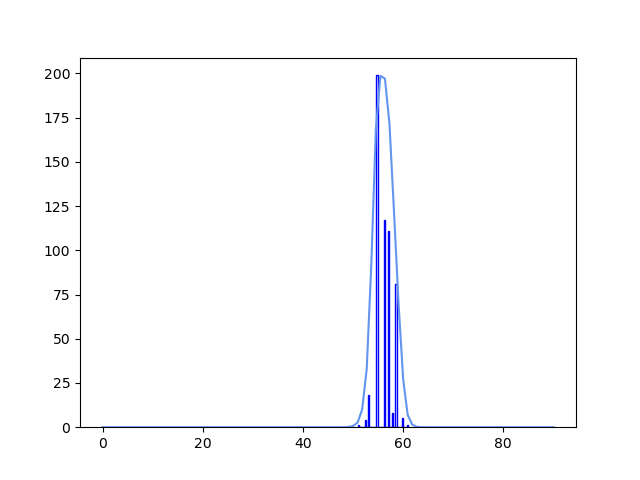

In [83]:

from sklearn.neighbors import KernelDensity
a = angles.reshape(-1,1)

kde = KernelDensity(kernel='gaussian', bandwidth=3).fit(a)

kde.score_samples(a)

X_plot = np.linspace(0, 90, 100)[:, np.newaxis] 

fig, ax = plt.subplots() 
  
  
# Calculating the density using the gaussian kernel with bandwidth 0.5 
kde = KernelDensity(kernel='gaussian', bandwidth=1).fit(a) 
  
# Calculating the log of the probability density function 
log_dens = kde.score_samples(X_plot) 
  
# Plotting the density curve 
ax.plot( 
    X_plot[:, 0], 
    np.exp(log_dens)*1000, 
    color="cornflowerblue", 
    linestyle="-", 
    label="Gaussian kernel density"
) 
counts, bins = np.histogram(angles, bins = 40)
ax.stairs(counts, bins, color='blue')
  


### Rigid Angle Graph Hopping  

924


0.95613337

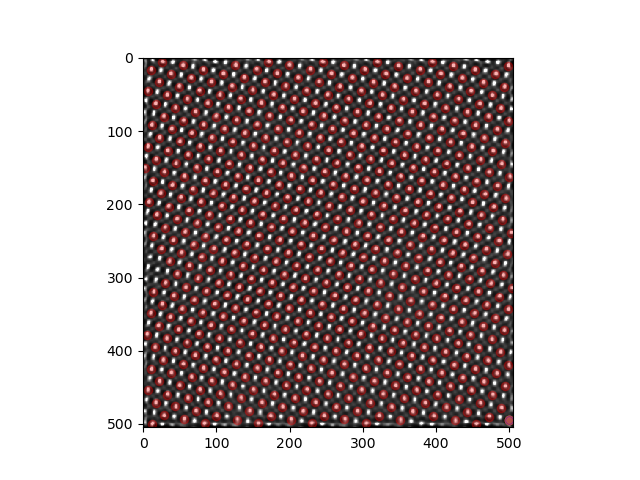

In [54]:
one_grain_indices = np.where(angles > 44)
one_grain = middle_atoms[one_grain_indices]
one_grain_angle = np.median(one_grain[:, 2]%np.radians(60))

two_grain_indices = np.where(angles < 44)
two_grain = middle_atoms[two_grain_indices]
two_grain_angle = np.median(two_grain[:, 2]%np.radians(60))

gamma = np.radians(layer.cell.angles()[2])

one_grain[100]
plt.figure()
plt.imshow(image.T, interpolation='nearest',cmap='gray', vmax=np.median(np.array(image))+3*np.std(np.array(image)))
#plt.scatter(one_grain[:, 0], one_grain[:, 1], c='blue', alpha = 0.2)

init = np.argmin(np.linalg.norm(blobs[:,:2]- [674, 594], axis=1))
#init = np.argmin(np.linalg.norm(blobs[:,:2]- [610, 552], axis=1))

plt.scatter(blobs[init][0], blobs[init][1], c='orange')
projection_tags = {'lattice_vector': {'a': np.array([np.cos(one_grain_angle)*21, np.sin(one_grain_angle)*21]),
                                      'b': np.array([np.cos(one_grain_angle+gamma)*21, np.sin(one_grain_angle+gamma)*21]) },
                   'allowed_variation': 1.5,
                   'distance_unit_cell':  21*1.04}
layer.info['projection'] = projection_tags
hop1, ideal = pyTEMlib.graph_tools.breadth_first_search2(blobs[:,:2], init, layer)
projection_tags = {'lattice_vector': {'a': np.array([np.cos(two_grain_angle)*21, np.sin(two_grain_angle)*21]),
                                      'b': np.array([np.cos(two_grain_angle+gamma)*21, np.sin(two_grain_angle+gamma)*21]) },
                   'allowed_variation': 1.5,
                   'distance_unit_cell':  21*1.04}
layer.info['projection'] = projection_tags
#init = np.argmin(np.linalg.norm(blobs[:,:2]- [574, 520], axis=1))

print(init)
hop2, ideal = pyTEMlib.graph_tools.breadth_first_search2(blobs[:,:2], init, layer)

plt.scatter(hop1[:,0], hop1[:,1], c='red', alpha = 0.3)
plt.scatter(hop2[:,0], hop2[:,1], c='blue', alpha = 0.3)


one_grain_angle

(545, 3)


1.0460007

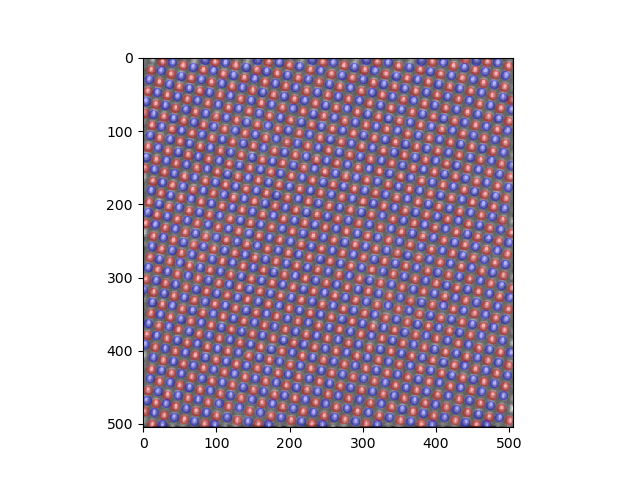

In [84]:
one_grain_indices = np.argmax(angles)
one_grain = middle_atoms # [one_grain_indices]
print(one_grain.shape)
one_grain_angle = np.max(one_grain[:, 2]%np.radians(60))


gamma = np.radians(layer.cell.angles()[2])
length = 22
plt.close('all')
plt.figure()
plt.imshow(image.T, interpolation='nearest',cmap='gray', vmax=np.median(np.array(image))+3*np.std(np.array(image)))
#plt.scatter(one_grain[:, 0], one_grain[:, 1], c='blue', alpha = 0.2)

init = np.argmin(np.linalg.norm(blobs[:,:2]- [812, 199], axis=1))

#init = np.argmin(np.linalg.norm(blobs[:,:2]- [610, 552], axis=1))
# init = 102
#plt.scatter(blobs[init][0], blobs[init][1], c='orange')
projection_tags = {'lattice_vector': {'a': np.array([np.cos(one_grain_angle)*length, np.sin(one_grain_angle)*length]),
                                      'b': np.array([np.cos(one_grain_angle+gamma)*length, np.sin(one_grain_angle+gamma)*length]) },
                   'allowed_variation': 5,
                   'distance_unit_cell':  length*1.04}
layer.info['projection'] = projection_tags
hop1, ideal = pyTEMlib.graph_tools.breadth_first_search2(blobs[:,:2], init, layer)
init = np.argmin(np.linalg.norm(blobs[:,:2]- [89, 989], axis=1))

hop2, ideal = pyTEMlib.graph_tools.breadth_first_search2(blobs[:,:2], init, layer)
plt.scatter(hop1[:,0], hop1[:,1], c='red', alpha = 0.3)
plt.scatter(hop2[:,0], hop2[:,1], c='blue', alpha = 0.3)


one_grain_angle

## Structure Anlysis

### Find all unit cells

In [85]:
import ase
positions = hopped_atoms.copy()
positions[:,2] = 0
atoms = ase.Atoms('Sr'*len(positions),
             positions=positions,
             cell=[image.shape[0],image.shape[1],0],
             pbc=[0, 0, 0])
atoms.info['bond_radii'] = [3] * len(positions)
graph_dictionary = pyTEMlib.graph_tools.find_polyhedra(atoms)

len(positions), len (graph_dictionary['cyclicity'])

extent [506. 505.   0.]
Find interstitials (finding centers for different elements takes a bit)


  0%|          | 0/1124 [00:00<?, ?it/s]

(575, 512)

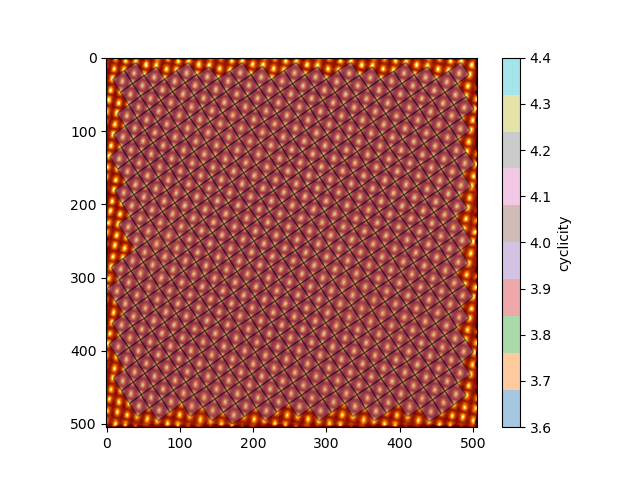

In [87]:
from matplotlib.collections import PatchCollection
from matplotlib import cm
import matplotlib
centers =  graph_dictionary['centers']
cyclicity = graph_dictionary['cyclicity']

unit_cells = PatchCollection(graph_dictionary['polygons'], alpha=0.4, cmap=matplotlib.cm.tab10)
plt.figure()
plt.imshow(image.T,  cmap = 'afmhot')

unit_cells.set_array(cyclicity)
unit_cells.set_edgecolor('black')
plt.gca().add_collection(unit_cells)
#plt.scatter(centers[:,0],centers[:,1],color='blue',alpha=0.5, s = 3)
#plt.scatter(hopped_atoms[:,0], hopped_atoms[:,1], c='red', alpha = 0.3)
cbar = plt.colorbar(unit_cells, label='cyclicity')

## Appendix

### Demon Registration

Here we use the **Diffeomorphic Demon Non-Rigid Registration** as provided by **simpleITK**.  

Please Cite: 
* [simpleITK](http://www.simpleitk.org/SimpleITK/project/parti.html)
    
    and
    
* [T. Vercauteren, X. Pennec, A. Perchant and N. Ayache *Diffeomorphic Demons Using ITK\'s Finite Difference Solver Hierarchy* The Insight Journal, 2007](http://hdl.handle.net/1926/510)

This Non-Rigid Registration consists of the following steps:

- determine ``reference`` image
    - For this we use the average of the rigid registered stack
    - this averaged stack is then smeared with a Gaussian of sigma 2 pixel to reduce noise
    - under the assumption that high frequency scan distortions cancel out over several images, we, therefore, obtained the center of mass of the atoms. 

- perform the ``demon registration`` filter to determine a distortion matrix
    - each single image of a stack is first smeared with a Gaussian of sigma of 2pixels
    - then the deformation matrix is determined for these images
    - the deformation matrix is a matrix where each pixel has a vector ( x, and y value) for the relative shift of this pixel.
    
- This deformation matrix is used to ``transform`` the image
	- The transformation is performed on the original image.
	- Important, here, is to set the interpolator method, (the image needs to be interpolated because the new pixels are not on an integer grid.)
    
    
Let's see what the different interpolators do.

|Method	| RMS contrast |	Standard |	Mean |
|-------|:--------------|:-------------|:-------|
|original   |0.1965806	|0.07764114	|0.3949583
|Linear	    |0.20159315	|0.079470366	|0.39421165
|BSpline	|0.20162606	|0.0794831 	|0.39421043
|Gaussian	|0.14310582	|0.056414302 	|0.39421389
|Hamming	|0.20163293	|0.07948672 	|0.39421496

The Gaussian interpolator as the only one seems to smear the signal.

We will use the ``Bspline`` method a fast and simple method that does not introduce spurious features and does not smear the signal.


#### Full Code of Demon registration 

In [ ]:
import simpleITK as sitk

def DemonReg(cube, verbose = False):
    """
    Diffeomorphic Demon Non-Rigid Registration 
    Usage:
    ------
    DemReg = DemonReg(cube, verbose = False)

    Input:
        cube: stack of image after rigid registration and cropping
    Output:
        DemReg: stack of images with non-rigid registration

    Dempends on:
        simpleITK and numpy
    
    Please Cite: http://www.simpleitk.org/SimpleITK/project/parti.html
    and T. Vercauteren, X. Pennec, A. Perchant and N. Ayache
    Diffeomorphic Demons Using ITK\'s Finite Difference Solver Hierarchy
    The Insight Journal, http://hdl.handle.net/1926/510 2007
    """
    
    DemReg =  np.zeros_like(cube)
    nimages = cube.shape[0]
    print(nimages)
    # create fixed image by summing over rigid registration

    fixed_np = np.average(current_dataset, axis=0)

    fixed = sitk.GetImageFromArray(fixed_np)
    fixed = sitk.DiscreteGaussian(fixed, 2.0)

    #demons = sitk.SymmetricForcesDemonsRegistrationFilter()
    demons = sitk.DiffeomorphicDemonsRegistrationFilter()

    demons.SetNumberOfIterations(200)
    demons.SetStandardDeviations(1.0)

    resampler = sitk.ResampleImageFilter()
    resampler.SetReferenceImage(fixed);
    resampler.SetInterpolator(sitk.sitkBspline)
    resampler.SetDefaultPixelValue(0)

    done = 0
        
    for i in range(nimages):
        if done < int((i+1)/nimages*50):
            done = int((i+1)/nimages*50)
            sys.stdout.write('\r')
            # progress output :
            sys.stdout.write("[%-50s] %d%%" % ('*'*done, 2*done))
            sys.stdout.flush()
        
        moving = sitk.GetImageFromArray(cube[i])
        movingf = sitk.DiscreteGaussian(moving, 2.0)
        displacementField = demons.Execute(fixed,movingf)
        outTx = sitk.DisplacementFieldTransform( displacementField )
        resampler.SetTransform(outTx)
        out = resampler.Execute(moving)
        DemReg[i,:,:] = sitk.GetArrayFromImage(out)
        #print('image ', i)
        
    
    print(':-)')
    print('You have succesfully completed Diffeomorphic Demons Registration')
    
    return DemReg
